Data Loading & Basic Exploration

In [62]:
import pandas as pd
import matplotlib.pyplot as plt

In [63]:
pwd

'/drive/notebooks'

1. Load the crop_yield.csv file into a Pandas DataFrame.

In [64]:
crop_df=pd.read_csv('crop_yield.csv')

2. Display the first 10 rows to give an overview of the data.

In [65]:
crop_df.head(10)

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.0,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.0,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.0,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,NaN,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.0,05/01/2023,Faisalabad,Rabi,No,30000
5,F006,Rice,2000.0,6.0,06/01/2023,Faisalabad,Rabi,Yes,40000
6,F007,Maize,1500.0,6.0,07/01/2023,Faisalabad,Rabi,No,30000
7,F008,Wheat,1500.0,5.0,08/01/2023,Lahore,Rabi,No,30000
8,F009,Wheat,2000.0,5.0,09/01/2023,Faisalabad,Rabi,Yes,40000
9,F010,Wheat,1500.0,3.0,10/01/2023,Faisalabad,Rabi,Yes,30000


3. Check for missing values in each column and display the result.

In [66]:
crop_df.isna().sum()

FARM_ID              0
CROP_TYPE            0
YIELD_KG           330
AREA_ACRES         144
HARVEST_DATE         0
DISTRICT           126
SEASON               0
FERTILIZER_USED    318
YIELD_VALUE          0
dtype: int64

4. View the data types of all columns.

In [67]:
crop_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   FARM_ID          3000 non-null   str    
 1   CROP_TYPE        3000 non-null   str    
 2   YIELD_KG         2670 non-null   float64
 3   AREA_ACRES       2856 non-null   float64
 4   HARVEST_DATE     3000 non-null   str    
 5   DISTRICT         2874 non-null   str    
 6   SEASON           3000 non-null   str    
 7   FERTILIZER_USED  2682 non-null   str    
 8   YIELD_VALUE      3000 non-null   int64  
dtypes: float64(2), int64(1), str(6)
memory usage: 140.7 KB


5. Get the statistical summary of all numeric columns.

In [68]:
crop_df.describe()

,YIELD_KG,AREA_ACRES,YIELD_VALUE
count,2670.000000,2856.000000,3000.000000
mean,2014.232210,4.420168,39657.780000
std,407.846962,0.979259,8405.078755
min,1500.000000,3.000000,20068.000000
25%,1500.000000,4.000000,30000.000000
50%,2000.000000,4.000000,40000.000000
75%,2500.000000,5.000000,50000.000000
max,2500.000000,6.000000,50000.000000


6. Get the statistical summary of all objective columns. 

In [69]:
crop_df.describe(include = 'object')

<ipython-input-69-89b6561366f8>:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  crop_df.describe(include = 'object')


,FARM_ID,CROP_TYPE,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED
count,3000,3000,3000,2874,3000,2682
unique,3000,4,3000,4,2,2
top,F001,Wheat,01/01/2023,Faisalabad,Rabi,Yes
freq,1,1158,1,936,1528,1776


In [70]:
crop_df.shape

(3000, 9)

Data Cleaning 

In [71]:
clean=crop_df.copy()

7. Remove all rows where the YIELD_KG column has missing.

In [72]:
clean=clean.dropna(subset=['YIELD_KG'])

8. Fill missing values in the AREA_ACRES column with the mean of that column.

In [73]:
clean=clean.fillna(clean['AREA_ACRES'].mean())

9. Replace missing values in the DISTRICT column with the string 'Unknown'.

In [74]:
clean['DISTRICT']=clean['DISTRICT'].fillna('Unknown')

10. Replace missing values in the FERTILIZER_USED column with the string 'No'.

In [75]:
clean['FERTILIZER_USED']=clean['FERTILIZER_USED'].fillna('NO')

11. Replace missing values in the YIELD_VALUE column with the mean of the column.

In [76]:
clean=clean.fillna(clean['YIELD_VALUE'].mean())

12. Convert the HARVEST_DATE column to datetime format.

In [77]:
clean['HARVEST_DATE']=pd.to_datetime(clean['HARVEST_DATE'],format='%d/%m/%Y',errors='coerce')

13. Remove the letter 'F' from the FARM_ID column and convert the result to an
integer.

In [78]:
clean['FARM_ID']=clean['FARM_ID'].str.replace('F','').astype(int)

14. Re-check missing values in the data again after cleaning.

In [79]:
clean.isna().sum()

FARM_ID            0
CROP_TYPE          0
YIELD_KG           0
AREA_ACRES         0
HARVEST_DATE       0
DISTRICT           0
SEASON             0
FERTILIZER_USED    0
YIELD_VALUE        0
dtype: int64

15. Re-check the data types of all columns again after cleaning. 

In [80]:
clean.info()

<class 'pandas.DataFrame'>
Index: 2670 entries, 0 to 2999
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   FARM_ID          2670 non-null   int32         
 1   CROP_TYPE        2670 non-null   str           
 2   YIELD_KG         2670 non-null   float64       
 3   AREA_ACRES       2670 non-null   float64       
 4   HARVEST_DATE     2670 non-null   datetime64[us]
 5   DISTRICT         2670 non-null   object        
 6   SEASON           2670 non-null   str           
 7   FERTILIZER_USED  2670 non-null   object        
 8   YIELD_VALUE      2670 non-null   int64         
dtypes: datetime64[us](1), float64(2), int32(1), int64(1), object(2), str(2)
memory usage: 156.4+ KB


Data Analysis and Visualization

16. Calculate the total yield of each type of crop.

In [81]:
total_yield = clean.groupby('CROP_TYPE')['YIELD_KG'].sum()
total_yield

CROP_TYPE
Maize        1112500.0
Rice         1638000.0
Sugarcane     592000.0
Wheat        2035500.0
Name: YIELD_KG, dtype: float64

17. Plot a bar chart of Total Yield by Crop Type (KG).

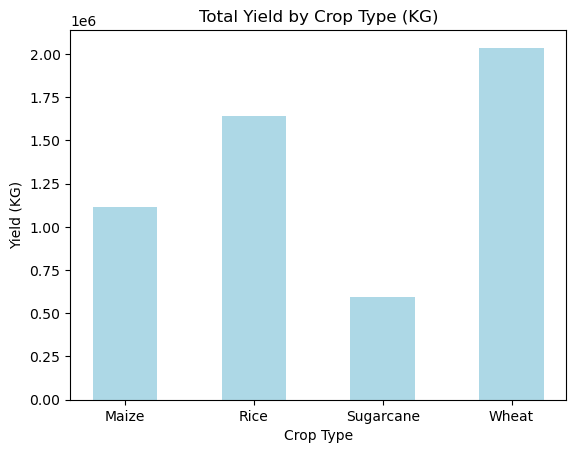

In [82]:
categories =total_yield.index
values=total_yield.values
plt.bar(categories, values, color='lightblue', width=0.5)
plt.xlabel('Crop Type')
plt.ylabel('Yield (KG)')
plt.title('Total Yield by Crop Type (KG)')
plt.show()

18. Create a pivot table summarizing total yield by harvest date.

In [83]:
table=clean.pivot_table(index='HARVEST_DATE', values='YIELD_KG',aggfunc='sum')
table

,YIELD_KG
HARVEST_DATE,
2023-01-01,1500.0
2023-01-02,1500.0
2023-01-03,2500.0
2023-01-04,1500.0
2023-01-05,1500.0
...,...
2031-03-15,1500.0
2031-03-16,2000.0
2031-03-17,2000.0


Plot a line chart showing the yield trend over time from the pivot table

<ipython-input-94-a34283abae5f>:8: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig('crop_yield_trend.png')
<ipython-input-94-a34283abae5f>:8: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig('crop_yield_trend.png')


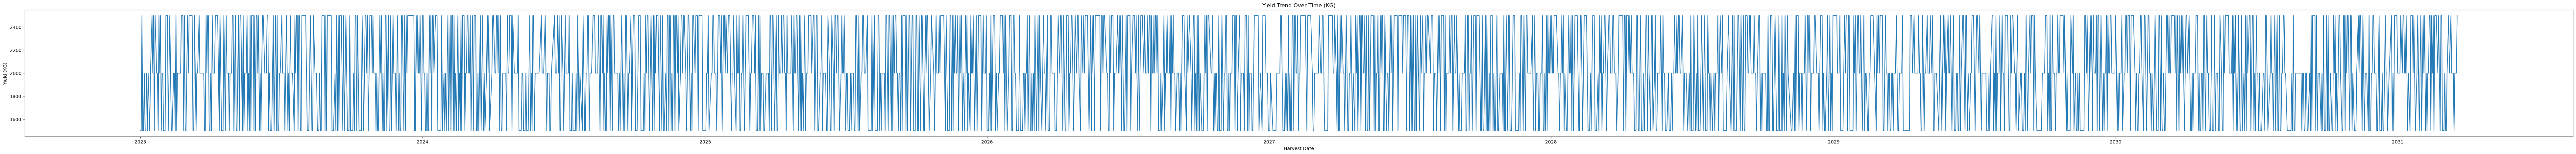

In [94]:
category = table.index
values = table.values
plt.figure(figsize=(100,5))
plt.plot(category, values)
plt.xlabel('Harvest Date')
plt.ylabel('Yield (KG)')
plt.title('Yield Trend Over Time (KG)')
plt.savefig('crop_yield_trend.png')
plt.show()